In [5]:
%pip install matplotlib numpy pandas scikit-learn

  Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (137 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_6

In [1]:
import matplotlib.pyplot as pyplot
import numpy as np 
import pandas as pd 
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('datos33_rellenado.csv')
columnas_analisis=["Peso","Altura","IMC"]
x_seleccion=df[columnas_analisis]
x_limpio=x_seleccion.dropna()
scaler=StandardScaler()
x=scaler.fit_transform(x_limpio)
print(f"Dataset cargado correctamente")
print(f"Cantidad total de filas procesables: {x.shape[0]}")
print(f"Cantidad total de variables evaluadas: {x.shape[1]}")

Dataset cargado correctamente
Cantidad total de filas procesables: 184
Cantidad total de variables evaluadas: 3


In [6]:
print(np.isnan(x).sum())

0


In [4]:
rango_k=[2,3,4,5,6]
print("---Evaluacion de Coeficiente de Silueta---")
for n_clusters in rango_k:
    clusterer=KMeans(n_clusters=n_clusters, random_state=42, n_init="auto")
    cluster_labels=clusterer.fit_predict(x)
    silhouette_avg=silhouette_score(x, cluster_labels)
    print(f"Para n_clusters={n_clusters}, el Coeficiente de Silueta es: {silhouette_avg}")

---Evaluacion de Coeficiente de Silueta---
Para n_clusters=2, el Coeficiente de Silueta es: 0.35311814870580227
Para n_clusters=3, el Coeficiente de Silueta es: 0.31204067585004625
Para n_clusters=4, el Coeficiente de Silueta es: 0.35615119279821167
Para n_clusters=5, el Coeficiente de Silueta es: 0.3553955964765713
Para n_clusters=6, el Coeficiente de Silueta es: 0.3252826590157946


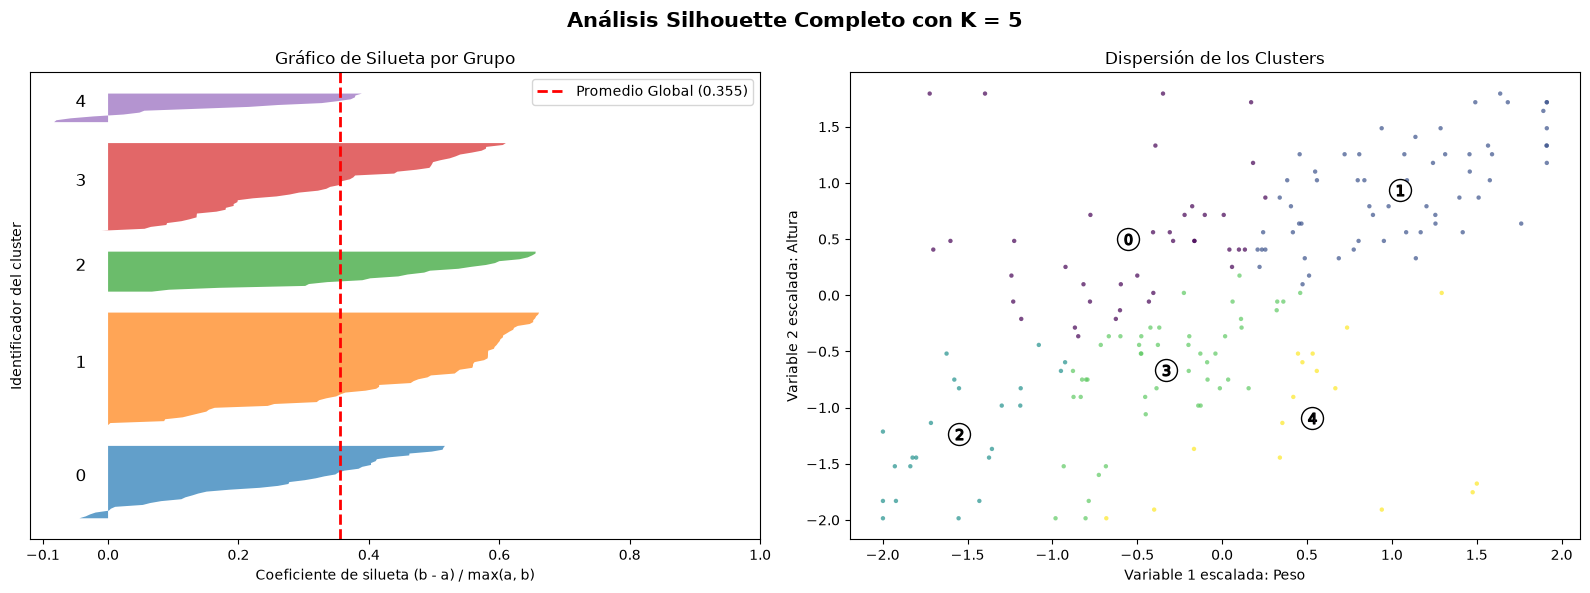

In [5]:
# DEFINE AQUÍ TU K GANADOR BASADO EN LA CELDA 3
k_elegido = 5

# Configuración de la figura (Panel izquierdo: Siluetas, Panel derecho: Puntos)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Entrenar el modelo final con el K seleccionado
modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init="auto")
etiquetas = modelo_final.fit_predict(x)
valores_silueta = silhouette_samples(x, etiquetas)
score_global = silhouette_score(x, etiquetas)

y_limite_inferior = 10
for i in range(k_elegido):
# Filtrar y ordenar las siluetas del cluster actual
 siluetas_cluster_i = valores_silueta[etiquetas == i]
 siluetas_cluster_i.sort()

 tamaño_cluster_i = siluetas_cluster_i.shape[0]
 y_limite_superior = y_limite_inferior + tamaño_cluster_i

# Dibujar el área del cluster con un color asignado automáticamente
 ax1.fill_betweenx(
 np.arange(y_limite_inferior, y_limite_superior),
 0,
 siluetas_cluster_i,
alpha=0.7,
 )

# Colocar el número identificador del cluster en el centro de su bloque
 ax1.text(
 -0.05, y_limite_inferior + 0.5 * tamaño_cluster_i, str(i), fontsize=12
 )
 y_limite_inferior = y_limite_superior + 10

# Propiedades del gráfico de Siluetas (Izquierda)
ax1.set_title("Gráfico de Silueta por Grupo", fontsize=12)
ax1.set_xlabel("Coeficiente de silueta (b - a) / max(a, b)")
ax1.set_ylabel("Identificador del cluster")
ax1.axvline(
x=score_global,
color="red",
linestyle="--",
linewidth=2,
label=f"Promedio Global ({score_global:.3f})",
)
ax1.set_yticks([])
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
ax1.legend(loc="upper right")

# Propiedades de la gráfica de Dispersión (Derecha)
# Nota: Grafica las 2 primeras columnas elegidas en la Celda 2
ax2.scatter(x[:, 0], x[:, 1], marker=".", s=40, lw=0, alpha=0.7, c=etiquetas)

# Dibujar los centroides generados por el algoritmo
centros = modelo_final.cluster_centers_
ax2.scatter(
 centros[:, 0],
 centros[:, 1],
marker="o",
c="white",
alpha=1,
s=250,
edgecolor="k",
)

for i, c in enumerate(centros):
 ax2.scatter(c[0], c[1], marker=f"${i}$", alpha=1, s=60, edgecolor="k")

ax2.set_title("Dispersión de los Clusters", fontsize=12)
ax2.set_xlabel(f"Variable 1 escalada: {columnas_analisis[0]}")
ax2.set_ylabel(f"Variable 2 escalada: {columnas_analisis[1]}")

plt.suptitle(
 f"Análisis Silhouette Completo con K = {k_elegido}",
fontsize=15,
fontweight="bold",
)
plt.tight_layout()
plt.show()


In [2]:
# Muestra los valores únicos de cada columna
for col in columnas_analisis:
    print(f"Valores únicos en {col}:", df[col].unique())

NameError: name 'columnas_analisis' is not defined